Today's topics:

* reading functions, loops, and conditionals
* `curve_fit` and its residuals
* `minimize`, RMSE, and an unexplained reading
* a fitted plane and a contour plot

# How fast lithium-ion cells fade

A lithium-ion cell holds a little less charge after every charge and discharge cycle.
After a few hundred cycles, a laptop battery lasts noticeably less time.

The charge a cell holds is its **capacity**, in ampere-hours (Ah).
The cells in this lecture are rated 3.0 Ah when new.

The question for today: how fast does a cell fade, and what makes it fade faster?

> Midterm 2 is on Wednesday, on paper: 50 minutes, one page (one side) of handwritten notes, and no electronic devices.

Today we practice reading code and its printed output, as you'll do on the exam.
Predict each result before we run the cell, then explain it in one or two sentences.

> The cell data in this lecture are synthetic, made up for this review.

# Functions, loops, and conditionals

## A function and a loop

One cell was tested at five checkpoints.
The function converts a capacity to the percent of the rated capacity that remains, and to the capacity lost.

The loop labels each checkpoint, and counts the checkpoints between 80% and 90%.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy import optimize

def retention(capacity_Ah, rated_Ah=3.0):
    """Percent of the rated capacity that remains, and the capacity lost in Ah.
    capacity_Ah:  measured capacity in Ah
    rated_Ah:     capacity of a new cell in Ah
    """
    return 100 * capacity_Ah / rated_Ah, rated_Ah - capacity_Ah

cycles = [100, 200, 300, 400, 500]
capacity_Ah = [2.91, 2.76, 2.55, 2.39, 2.31]

n_watch = 0
for i in range(len(cycles)):
    pct, lost_Ah = retention(capacity_Ah[i])
    if pct >= 90:
        print(cycles[i], 'cycles: good')
    elif pct >= 80:
        n_watch = n_watch + 1
        print(cycles[i], 'cycles: watch,', lost_Ah, 'Ah lost')
    else:
        print(cycles[i], 'cycles: end of life')
        break
print(n_watch)

100 cycles: good
200 cycles: good
300 cycles: watch, 0.4500000000000002 Ah lost
400 cycles: end of life
1


The function returns two values, and `pct, lost_Ah = ...` unpacks them in that order.
The `rated_Ah=3.0` in the `def` line is a default, used whenever we don't give a rated capacity in the call.

The `break` ends the loop at the first end-of-life checkpoint.

## `continue`, and a second rated capacity

A `continue` skips the rest of the loop body for one pass and goes on to the next.
A call can name an input to replace its default.

Let's run the same function on a smaller cell, rated 2.0 Ah.

In [2]:
pct, lost_Ah = retention(1.8, rated_Ah=2.0)
print(pct, lost_Ah)  # percent remaining, Ah lost

90.0 0.19999999999999996


### [Check your understanding]

Predict the output before you run each block, then use Python to check it.

1. Read this loop and predict its output. Run it to check your answer.

```python
temps_C = [25, 35, 45, 55, 65]
cap_Ah = [2.9, 2.8, 2.5, 2.4, 2.1]

for i in range(len(temps_C)):
    if temps_C[i] < 30:
        continue
    if cap_Ah[i] < 2.45:
        print(temps_C[i], 'C: too low')
        break
    print(temps_C[i], 'C: ok')
```

2. Predict the two printed percentages, then run the calls to check.

```python
pct, lost_Ah = retention(1.5)
print(pct)
pct, lost_Ah = retention(1.5, 2.5)
print(pct)
```

3. Suppose `retention` also displays `low` below 80%.
   What must it still give back for the first loop to work, and why?

# Fitting with `curve_fit`

## The data

One cell was cycled 1000 times and tested at 12 checkpoints.
`loss_pct` is the capacity lost, as a percent of the rated capacity.

We store the cycle count in hundreds of cycles, so the numbers in the fit stay small.

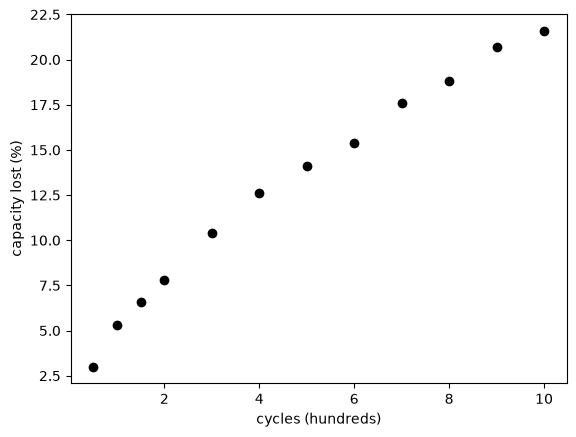

In [3]:
cycles = np.array([50, 100, 150, 200, 300, 400, 500, 600, 700, 800, 900, 1000])
loss_pct = np.array([3.0, 5.3, 6.6, 7.8, 10.4, 12.6, 14.1, 15.4, 17.6, 18.8, 20.7, 21.6])
n = cycles / 100   # hundreds of cycles

fig, ax = plt.subplots()
ax.plot(n, loss_pct, 'o', color='black')
ax.set_xlabel('cycles (hundreds)')
ax.set_ylabel('capacity lost (%)')
plt.show()

## A power law

The loss rises quickly at first and then more slowly.
A power law can have that shape when its exponent is between 0 and 1, so let's fit one and look at `b`.

In [4]:
def fade_model(n, a, b):
    """Percent of capacity lost, from a * n**b.
    n:  cycles in hundreds
    a:  percent lost at n = 1, in %
    b:  exponent, no units
    """
    return a * n**b

popt, pcov = optimize.curve_fit(fade_model, n, loss_pct, p0=[1, 1])
print('a, b:', popt)

popt_2, pcov_2 = optimize.curve_fit(fade_model, n, loss_pct, p0=[10, 0.2])
print('a, b:', popt_2)

a, b: [5.13972745 0.62731567]
a, b: [5.13972749 0.62731567]


The fit is the same from both starting guesses.
The values go in the order of the `def` line: `a` first, then `b`.

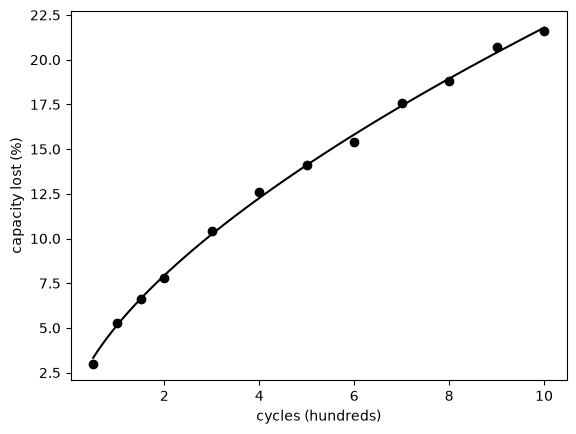

In [5]:
n_line = np.linspace(0.5, 10, 100)

fig, ax = plt.subplots()
ax.plot(n, loss_pct, 'o', color='black')
ax.plot(n_line, fade_model(n_line, *popt), '-', color='black')
ax.set_xlabel('cycles (hundreds)')
ax.set_ylabel('capacity lost (%)')
plt.show()

## Residuals

A residual is the data minus the fit.
Let's plot the residuals of the power law, and of a straight line fitted to the same readings.

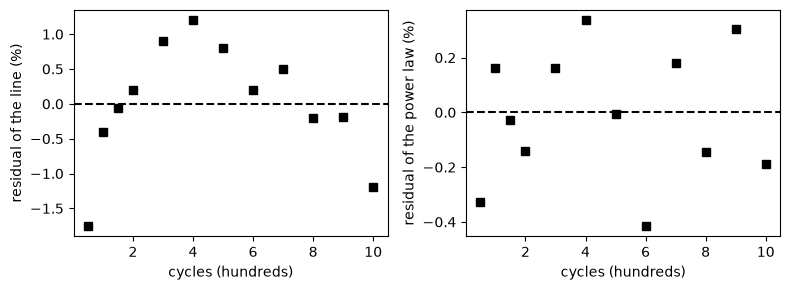

In [6]:
line = stats.linregress(n, loss_pct)
res_line = loss_pct - (line.slope * n + line.intercept)
res_power = loss_pct - fade_model(n, *popt)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(n, res_line, 's', color='black')
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_xlabel('cycles (hundreds)')
axes[0].set_ylabel('residual of the line (%)')
axes[1].plot(n, res_power, 's', color='black')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_xlabel('cycles (hundreds)')
axes[1].set_ylabel('residual of the power law (%)')
fig.tight_layout()
plt.show()

The residuals of the power law scatter around zero with no obvious pattern.
The residuals of the line are negative at the first checkpoint, positive in the middle, and negative at the end.

### [Check your understanding]

1. Suppose the cycle count doubles.
   Does the fitted loss double, more than double, or less than double?
   Use the printed exponent to explain your answer.
2. Look at the left panel of residuals.
   At which cycle counts does the straight line predict too much loss, and at which too little?

# Fitting with `minimize`

## The same fit as a minimum

The objective takes the parameters and returns the sum of the squared residuals.
We call `minimize` to find the parameters that make it smallest.

In [7]:
def sse_fade(params):
    a, b = params
    residuals = loss_pct - fade_model(n, a, b)
    return np.sum(residuals**2)

res = optimize.minimize(sse_fade, [3, 0.5])
a_fit, b_fit = res.x
print('a, b:', res.x)
print('SSE:', res.fun)
print(res.success)

a, b: [5.13972845 0.62731557]
SSE: 0.6457671558948954
True


`res.fun` is the sum of the squared residuals at the fitted parameters.

## Scoring the fit

The RMSE is in the units of the data, so we can compare forms.

In [8]:
def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

print('power law RMSE:', rmse(loss_pct, fade_model(n, *res.x)))
print('line RMSE:', rmse(loss_pct, line.slope * n + line.intercept))

power law RMSE: 0.23197829566127076
line RMSE: 0.8146986805211032


## One reading that doesn't fit

Suppose the 400-cycle reading had come back as 4.0 % instead of 12.6 %.
The other readings around it are 10.4 % and 14.1 %, and the test log has no note about it.

In [9]:
alt_pct = np.array([3.0, 5.3, 6.6, 7.8, 10.4, 4.0, 14.1, 15.4, 17.6, 18.8, 20.7, 21.6])

def sse_alt(params):
    a, b = params
    return np.sum((alt_pct - fade_model(n, a, b))**2)

def mae_alt(params):
    a, b = params
    return np.mean(np.abs(alt_pct - fade_model(n, a, b)))

res_ls = optimize.minimize(sse_alt, [3, 0.5])
res_mae = optimize.minimize(mae_alt, [3, 0.5])

print('without 4.0%:', a_fit, b_fit)
print('least squares:', res_ls.x)
print('minimum MAE:', res_mae.x)
print(res_mae.success)

without 4.0%: 5.139728449419596 0.627315568750713
least squares: [4.06950733 0.72748276]
minimum MAE: [5.16109516 0.62171188]
False


`success` is False here because the solver stopped with a precision-loss message.
Judge the line by its residuals or a plot, not by `success`.

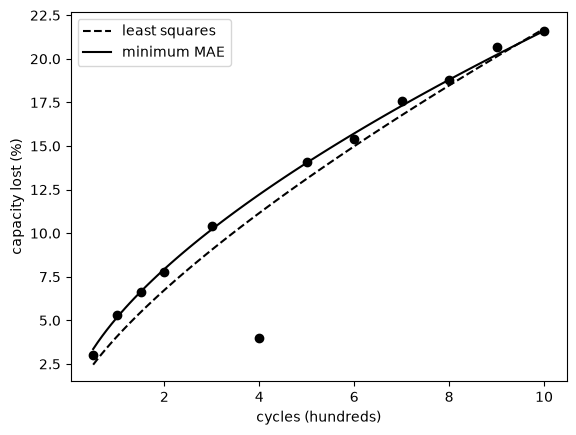

In [10]:
fig, ax = plt.subplots()
ax.plot(n, alt_pct, 'o', color='black')
ax.plot(n_line, fade_model(n_line, *res_ls.x), '--', color='black', label='least squares')
ax.plot(n_line, fade_model(n_line, *res_mae.x), '-', color='black', label='minimum MAE')
ax.set_xlabel('cycles (hundreds)')
ax.set_ylabel('capacity lost (%)')
ax.legend()
plt.show()

Let's score each fitted curve with RMSE and MAE on the readings that include the 4.0 %.

In [11]:
for name, p in [('least squares', res_ls.x), ('minimum MAE', res_mae.x)]:
    miss = alt_pct - fade_model(n, *p)
    fit_rmse = np.sqrt(np.mean(miss**2))
    fit_mae = np.mean(np.abs(miss))
    print(name, 'RMSE, MAE:', fit_rmse, fit_mae)

least squares RMSE, MAE: 2.2275770596102222 1.311409501135434
minimum MAE RMSE, MAE: 2.3835189317247782 0.8523983568959145


### [Check your understanding]

1. The 4.0 % reading differs from the curve fitted to the other readings by about 8 percentage points, and a typical other reading misses by about 0.2.
   Compare 8 with 0.2 before and after squaring. How many times larger is the unusual miss in each case?
2. Use those two comparisons to explain why the fits rank differently on RMSE and MAE.
3. Write two sentences for the lab notebook: what we would check first about the 4.0 %, and what we would do with it afterward.

# A plane and a contour plot

## Two inputs

Fourteen cells were cycled 500 times, each at its own temperature and charge current.
`retention_pct` is the capacity left, as a percent of the rated capacity.

The code fits the plane `retention = a + b T + c I` by minimizing the mean squared residual.

In [12]:
temp_C = np.array([15, 25, 35, 45, 15, 25, 35, 45, 15, 25, 35, 45, 20, 40])
charge_A = np.array([1, 1, 1, 1, 2, 2, 2, 2, 4, 4, 4, 4, 3, 3])
retention_pct = np.array([95, 93, 93, 92, 95, 92, 90, 88, 89, 89, 86, 83, 89, 89])

def plane(T, I, a, b, c):
    return a + b * T + c * I

def mse_plane(params):
    a, b, c = params
    residuals = retention_pct - plane(temp_C, charge_A, a, b, c)
    return np.mean(residuals**2)

res_plane = optimize.minimize(mse_plane, [90, 0, 0])
a_p, b_p, c_p = res_plane.x
print('b, c:', b_p, c_p)  # percent per °C, percent per A
print(res_plane.success)

b, c: -0.15588252939599545 -2.1764700958021703
True


## Scoring and comparing the inputs

In [13]:
retention_fit = plane(temp_C, charge_A, *res_plane.x)
print('plane RMSE:', rmse(retention_pct, retention_fit))
print('mean RMSE:', np.std(retention_pct))

plane RMSE: 1.0356056158600906
mean RMSE: 3.2552939614588112


To compare the two inputs, we multiply each coefficient by the span of its input in the data.

In [14]:
temp_span = np.max(temp_C) - np.min(temp_C)
charge_span = np.max(charge_A) - np.min(charge_A)
print('temperature span, change:', temp_span, b_p * temp_span)
print('current span, change:', charge_span, c_p * charge_span)

temperature span, change: 30 -4.676475881879863
current span, change: 3 -6.529410287406511


## The contour plot

The bands show the fitted retention, yellow for more.
Each white circle is one of the 14 cells, placed at its temperature and charge current.

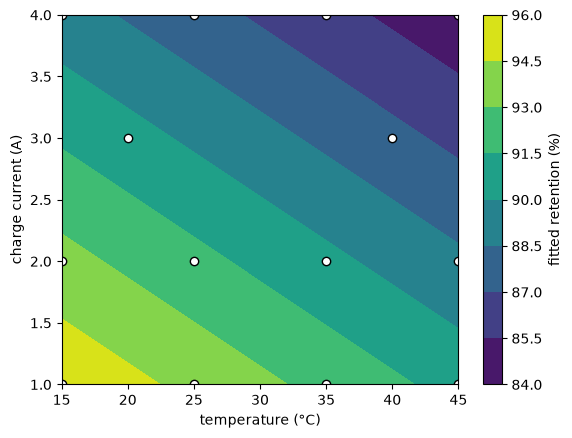

In [15]:
fig, ax = plt.subplots()
cs = ax.tricontourf(temp_C, charge_A, retention_fit, cmap='viridis')
ax.scatter(temp_C, charge_A, color='white', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('fitted retention (%)')
ax.set_xlabel('temperature (°C)')
ax.set_ylabel('charge current (A)')
plt.show()

### [Check your understanding]

1. A pack designer needs at least 90% retention after 500 cycles.
   Use the contour plot to find one tested temperature and current that meet it.
   Is the gap above 90% large compared with the plane's 1.0% RMSE?
2. Suppose we refit with the charge current in milliamps, so every current is 1000 times larger.
   Which of these change: `b`, `c`, the RMSE of the plane, and the change in retention over each input's span?

# Summary

* Defaults, returned values, `continue`, and `break` change how a function and loop run.
* `curve_fit` returns parameters in model order; residuals show where a fit misses.
* `minimize` reports parameters and the objective value; RMSE puts misses in data units.
* A plane uses two inputs, and its contour bands show equal fitted values.

## Further reading

* VanderPlas, *Python Data Science Handbook*, [Density and Contour Plots](https://jakevdp.github.io/PythonDataScienceHandbook/04.04-density-and-contour-plots.html), for contour plots on a regular grid
* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [Chapter 16, "Least Squares Regression"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.00-Least-Squares-Regression.html)
* [`scipy.optimize.curve_fit` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html)
* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
* Ramadass et al., [capacity fade of Li-ion cells at elevated temperature](https://doi.org/10.1016/S0378-7753(02)00473-1), for background on real cells